## Trabalho 1 da Disciplina UFSM00993 - Aprendizado de Máquina Profundo

### Você deverá implementar, usando exclusivamente NumPy e Matplotlib, uma Multi-layer Perceptron (MLP) para classificação de dados bidimensionais. O objetivo é compreender como a arquitetura da rede, as funções de ativação e o processo de otimização influenciam a capacidade de aprendizado de um modelo de aprendizado profundo.

#### 1. Considere o dataset fornecido em formato .json. Separe os dados adequadamente em subconjuntos de treino e validação. Considere normalizar os dados de treino e validação conforme estatísticas (média e desvio padrão) dos dados de treino de tal forma que os dados de treino normalizados tenham média zero e desvio padrao unitário. Em todos seus testes, atente para potenciais sobreajustes. Utilize uma seed fixa para separação dos dados e inicializações dos parâmetros dos modelos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
import time

In [2]:
rng = np.random.default_rng(7)  # seed fixa para ficar reproduzivel

In [3]:
print(f'número do dataset usado: {202510242 % 8}')

número do dataset usado: 2


In [4]:
# !wget https://raw.githubusercontent.com/tltsilveira/ufsm00993/main/dataset_2.json comentado só para não ficar baixando toda hora

In [5]:
with open("dataset_2.json", "r") as file:
    dataset = json.load(file)

X = np.array(dataset["X"], dtype=float)
y = np.array(dataset["y"], dtype=int)

In [6]:
X.shape, y.shape

((600, 2), (600,))

Com 600 dados, vou dividir agora em uma proporção 80/20, 80% dos dados para treino e 20% para validação. Depois, computo a média e desvio padrão somento no conjunto de treino para normalizar os conjuntos, evitando data leakage.

In [7]:
600 * 0.8

480.0

In [8]:
indexes = rng.permutation(len(X)) # permutação dos indices para separar aleatoriamente train e val

index_train = indexes[:480]
index_val = indexes[480:]

X_train = X[index_train]
y_train = y[index_train]
X_val = X[index_val]
y_val = y[index_val]

In [9]:
X_train.shape, y_train.shape, X_val.shape, y_val.shape

((480, 2), (480,), (120, 2), (120,))

In [10]:
y_train.sum() / len(y_train) # 51% dos dados de treino é classe 1

np.float64(0.5145833333333333)

In [11]:
y_val.sum() / len(y_val) # 45% dos dados de validacao é classe 1, tá razoavelmente estratificado

np.float64(0.4583333333333333)

agora, normalizar os dois conjuntos usando as estatísticas do conjunto de treino

In [12]:
mean_train = X_train.mean(axis=0)
std_train = X_train.std(axis=0)

mean_train, std_train

(array([ 0.06034041, -0.00356361]), array([1.74915666, 1.13727365]))

In [13]:
X_train_norm = (X_train - mean_train) / std_train
X_val_norm = (X_val - mean_train) / std_train

X_train_norm.shape, X_val_norm.shape

((480, 2), (120, 2))

In [14]:
X_train_norm.mean(axis=0), X_train_norm.std(axis=0)

(array([5.55111512e-17, 1.85037171e-17]), array([1., 1.]))

In [15]:
X_val_norm.mean(axis=0), X_val_norm.std(axis=0)

(array([-0.15553578,  0.03440187]), array([1.03422946, 1.06103242]))

#### 2. Implemente, utilizando apenas Python e NumPy, uma MLP com duas entradas, uma camada oculta com largura a ser escolhida e uma camada de saída adequada ao problema de classificação considerado. Cuide para que sua camada oculta tenha uma função de ativacao não-linear.

arquitetura inicial pensada: 2 units de entrada, 8 units na camada oculta, 1 unit de saida. na camada oculta uso da fun,ão de ativação relu e na de saída sigmoid.

y_hat = sig(relu(X @ W1 + b1) @ W2 + b2)

In [16]:
# funções de ativação usadas
def relu(x):
    return np.maximum(0, x)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [17]:
W1 = rng.normal(0, 1, size=(2, 8))
b1 = np.zeros((1, 8))
W2 = rng.normal(0, 1, size=(8, 1))
b2 = np.zeros((1, 1))


W1, b2, W2, b1

(array([[-0.97714544,  0.85343765, -0.51816969,  1.49830168, -0.77983936,
          0.38650199, -0.22728301, -0.75402181],
        [ 0.58767504, -0.15498257,  0.60321058, -0.04729151, -1.08581626,
         -0.10206924,  0.05195517,  0.95846295]]),
 array([[0.]]),
 array([[-0.90626901],
        [-0.03932985],
        [-1.72187873],
        [ 0.65149306],
        [-1.08148297],
        [-1.80635952],
        [-0.05921683],
        [ 1.10568496]]),
 array([[0., 0., 0., 0., 0., 0., 0., 0.]]))

In [18]:
def init_params(rng):
    W1 = rng.normal(0, 1, size=(2, 8))
    b1 = np.zeros((1, 8))
    W2 = rng.normal(0, 1, size=(8, 1))
    b2 = np.zeros((1, 1))
    return W1, b1, W2, b2


def forward(X, W1, b1, W2, b2):
    A1 = relu(X @ W1 + b1)
    y_hat = sigmoid(A1 @ W2 + b2)
    return y_hat

In [19]:
W1, b1, W2, b2 = init_params(rng)
y_hat = forward(X_train_norm, W1, b1, W2, b2)

In [20]:
y_hat.shape

(480, 1)

In [21]:
y_hat[:5]

array([[0.90711444],
       [0.00822699],
       [0.22376671],
       [0.01975817],
       [0.15623655]])

#### 3. Implemente manualmente uma função de perda adequada ao problema e suas respectivas funções de ativação na camada de saída. Considere e discuta as possibilidades de utilizar binary cross-entropy (BCE) em conjunto com a função sigmoide ou categorical cross-entropy (CCE) em conjunto com a função softmax.

para usar a saida sigmoid e binary cross-entropy se utiliza somente um neuronio de saida, com valores entre 0 e 1. já para usar a softmax e CCE seriam necessarios 2 neuronios, um para cada classe (0 e 1). como estou usando 1 neuronio para saida, vou seguir usando a BCE

In [22]:
def bce(y, y_hat):
    y_hat = y_hat.ravel() # deixar no formato vetor assim como y, (480, 1) -> (480,)
    y_hat = np.clip(y_hat, a_min=1e-12, a_max=1 - 1e-12) # evitar logaritmo indefinido log(0) ou log(1-1)
    return -np.mean((1 - y) * np.log(1 - y_hat) + y * np.log(y_hat))

In [23]:
bce(y_train, y_hat)

np.float64(1.4632724794983163)

#### 4. Inicialize os pesos utilizando a He initialization. Para uma camada com nin entradas, os pesos devem ser amostrados de uma distribuição normal com média zero e desvio-padrão σ = sqrt(2 / nin). Os vieses deverão ser inicializados com zero.

In [24]:
def he_init_params(rng):
    W1 = rng.normal(0, np.sqrt(2 / 2), size=(2, 8))
    b1 = np.zeros((1, 8))
    W2 = rng.normal(0, np.sqrt(2 / 8), size=(8, 1))
    b2 = np.zeros((1, 1))
    return W1, b1, W2, b2

In [25]:
W1, b1, W2, b2 = he_init_params(rng)
y_hat = forward(X_train_norm, W1, b1, W2, b2)

In [26]:
bce(y_train, y_hat)

np.float64(0.9811993763307262)

#### 5. Implemente manualmente o gradiente descendente. Determine analiticamente as derivadas da função de perda em relação a todos os pesos e vieses da MLP e implemente essas derivadas utilizando NumPy. Identifique textualmente o gradiente associado a cada parâmetro (matriz de pesos ou vetor de vieses) da rede.

gradiente descendente: theta <- theta - lr * grad

parametros: W2, b2, W1, b1

com: Z1 = XW1 + b1, A1 = relu(Z1), Z2 = A1W2 + b2, A2 = sig(Z2)

dZ2 = (A2 - y) / n

dW2 = A1^t dZ2

db2 = sum(dZ2)

dA1 = dZ2 W2^t

DZ1 = dA1 * d/relu(Z1)

dW1 = X^t dZ1

db1 = sum(dZ1)

com isso, temos os gradientes da camada oculta (dW1 e db1) e da camada de saída (DW2 e db2).

In [27]:
def backward(X, y, W2, Z1, A1, A2):
    y = y.reshape(-1, 1)
    n = len(y)

    dZ2 = (A2 - y) / n
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [28]:
def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    y_hat = sigmoid(A1 @ W2 + b2)
    return y_hat, A1, Z1

In [29]:
W1, b1, W2, b2 = he_init_params(rng)
y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)

In [30]:
dW1, db1, dW2, db2 = backward(X_train_norm, y_train, W2, Z1, A1, y_hat)

In [31]:
dW1, db1

(array([[-0.00630987, -0.00507719,  0.01405034, -0.00910593, -0.00019036,
         -0.06551105,  0.0014576 , -0.03440034],
        [-0.05089369, -0.01200334, -0.02002704, -0.00082607, -0.00012411,
         -0.01060455,  0.00340334, -0.06364992]]),
 array([[ 0.05271268,  0.01536126,  0.03136417, -0.00734703,  0.00018834,
          0.06260004, -0.00489044,  0.07165764]]))

In [32]:
dW2, db2

(array([[-0.08060128],
        [-0.00758905],
        [-0.14223745],
        [-0.14962751],
        [-0.01758913],
        [-0.06980848],
        [-0.02137401],
        [-0.10007304]]),
 array([[-0.17173954]]))

In [33]:
bce(y_train, y_hat)

np.float64(0.7691683372717297)

In [34]:
lr = 1e-2

W1 = W1 - lr * dW1
b1 = b1 - lr * db1
W2 = W2 - lr * dW2
b2 = b2 - lr * db2

In [35]:
y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)

In [36]:
bce(y_train, y_hat)

np.float64(0.7679667854134069)

#### 6. Durante o treinamento, registre o valor da função de perda a cada época. Mostre um gráfico contendo a evolução da perda nos conjuntos de treino e validação. Considere a biblioteca Matplotlib para isso e descreva os resultados.

In [37]:
history_loss_train = []
history_loss_val = []

epochs = 8500
lr = 5e-2

In [38]:
W1, b1, W2, b2 = he_init_params(rng)

In [39]:
for _ in range(epochs):
    # forward pass
    y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)
    history_loss_train.append(bce(y_train, y_hat))
    y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)
    history_loss_val.append(bce(y_val, y_hat_val))

    # backward pass
    dW1, db1, dW2, db2 = backward(X_train_norm, y_train, W2, Z1, A1, y_hat)

    # gradient descent
    W1 = W1 - lr * dW1
    b1 = b1 - lr * db1
    W2 = W2 - lr * dW2
    b2 = b2 - lr * db2

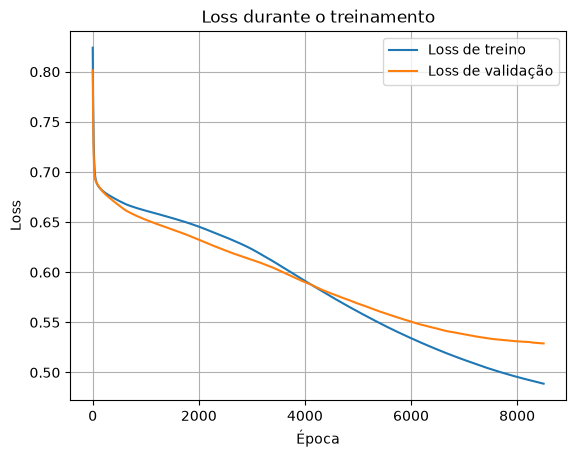

In [40]:
plt.plot(np.arange(epochs), history_loss_train, label='Loss de treino')
plt.plot(np.arange(epochs), history_loss_val, label='Loss de validação')
plt.title('Loss durante o treinamento')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

o modelo "aprendeu", com a loss de treino e validação diminuindo, mas só na época 8000 começou a ter um platô na validação. sem sobreajuste nesse número de épocas, sem que a loss de validação aumente, mas começou a crescer a diferença entre as duas curvas.

#### 7. Avalie a MLP utilizando, ao menos, as métricas acurácia, precisão, revocação e F1-score. Apresente tambem a matriz de confusão obtida nos conjuntos de treino e validação. Descreva os resultados.

primeiro, precisamos pegar as predições do modelo, vou usar o threshold de decisão como 0.5

In [41]:
def predict(X, W1, b1, W2, b2):
    prob_val, _, _ = forward(X, W1, b1, W2, b2)
    pred_val = (prob_val.ravel() >= 0.5).astype(int)
    return pred_val

In [42]:
def safe_div(num, den):
    return num / den if den != 0 else 0.0

def accuracy(tp, tn, fp, fn):
    return (tp + tn) / (tp + fp + tn + fn)

def precision(tp, tn, fp, fn):
    return safe_div(tn, tn + fn), safe_div(tp , tp + fp)   # (precisao classe 0, precisao classe 1)

def recall(tp, tn, fp, fn):
    return safe_div(tn , tn + fp), safe_div(tp , tp + fn)   # (recall classe 0, recall classe 1)

def f1_score(tp, tn, fp, fn):
    prec_0, prec_1 = precision(tp, tn, fp, fn)
    recall_0, recall_1 = recall(tp, tn, fp, fn)
    return safe_div(2 * prec_0 * recall_0 , prec_0 + recall_0), safe_div(2 * prec_1 * recall_1 , prec_1 + recall_1) # (f1 classe 0, f1 classe 1)

In [43]:
def evaluate(y, y_hat):
    gt_y = y.ravel()

    true_pos = np.sum((gt_y == 1) & (y_hat == 1))
    false_pos = np.sum((gt_y == 0) & (y_hat == 1))
    true_neg = np.sum((gt_y == 0) & (y_hat == 0))
    false_neg = np.sum((gt_y == 1) & (y_hat == 0))

    matriz = np.array([[true_neg, false_pos], [false_neg, true_pos]])
    acc = accuracy(true_pos, true_neg, false_pos, false_neg)
    prec = precision(true_pos, true_neg, false_pos, false_neg)
    rec = recall(true_pos, true_neg, false_pos, false_neg)
    f1 = f1_score(true_pos, true_neg, false_pos, false_neg)

    return acc, prec, rec, f1, matriz

In [44]:
pred_train = predict(X_train_norm, W1, b1, W2, b2)
pred_val = predict(X_val_norm, W1, b1, W2, b2)

In [45]:
def show_evaluation(results):
    acc, prec, rec, f1, matriz = results

    print(f'\nAcurácia: {acc:.3f}\n')

    print(f'{"Métrica":<12}{"Classe 0":>12}{"Classe 1":>12}')
    for metric, values in [('Precisão', prec), ('Revocação', rec), ('F1-score', f1)]:
        print(f'{metric:<12}{values[0]:>12.3f}{values[1]:>12.3f}')

    print('\nMatriz de confusão')
    print(f'{"":<12}{"Previsto 0":>12}{"Previsto 1":>12}')
    for classe, row in enumerate(matriz):
        print(f'{"Real " + str(classe):<12}{row[0]:>12}{row[1]:>12}')

In [46]:
results_train = evaluate(y_train, pred_train)
results_val = evaluate(y_val, pred_val)

In [47]:
show_evaluation(results_train)


Acurácia: 0.777

Métrica         Classe 0    Classe 1
Precisão           0.781       0.773
Revocação          0.751       0.802
F1-score           0.766       0.787

Matriz de confusão
              Previsto 0  Previsto 1
Real 0               175          58
Real 1                49         198


In [48]:
show_evaluation(results_val)


Acurácia: 0.750

Métrica         Classe 0    Classe 1
Precisão           0.818       0.692
Revocação          0.692       0.818
F1-score           0.750       0.750

Matriz de confusão
              Previsto 0  Previsto 1
Real 0                45          20
Real 1                10          45


o MLP teve uma acurácia de 0,77 no treino e 0,75 na validação, foi uma diferença bem pequena, então sem sinal de sobreajuste. no conjunto de validação, o F1-score foi 0,75 para as duas classes. o recall da classe 1 (0,81) foi maior que a da classe 0 (0,69). assim, ele reconhece melhor os exemplos da classe 1, ao custo de mais falsos positivos para essa classe.

#### 8. Avalie experimentalmente o impacto da largura da camada oculta. Compare diferentes configurações considerando a perda e as métricas de classificação no conjunto de validação. Descreva os resultados.

In [49]:
epochs = 100000
lr = 5e-2
patience = 200

experiment_hiddens = [8, 16, 32, 64, 128, 256, 512, 1024]

In [50]:
def he_init_params(rng, n_hidden):
    W1 = rng.normal(0, np.sqrt(2 / 2), size=(2, n_hidden))
    b1 = np.zeros((1, n_hidden))
    W2 = rng.normal(0, np.sqrt(2 / n_hidden), size=(n_hidden, 1))
    b2 = np.zeros((1, 1))
    return W1, b1, W2, b2

In [51]:
for n_units in experiment_hiddens:
    resultados = []
    print('='*80) 
    print(f'teste com {n_units} unidades na camada oculta:') 

    # uso de 5 seeds para inicialização dos pesos com a dimensão relativa a hidden units e analisar média e desvio padrao
    for seed in [7, 10, 15, 101, 200]:
        rng_model = np.random.default_rng(seed)
        W1, b1, W2, b2 = he_init_params(rng_model, n_units)

        # treinamento
        history_loss_train = []
        history_loss_val = []
        count_patience = 0
        best_val = 1e5
        for _ in range(epochs):
            # forward pass
            y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)
            history_loss_train.append(bce(y_train, y_hat))
            y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)

            # early stopping, com restore best weights
            loss_val = bce(y_val, y_hat_val)
            history_loss_val.append(loss_val)
            if loss_val < best_val:
                best_val = loss_val
                count_patience = 0
                best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
            else:
                count_patience += 1
                
            if count_patience >= patience:
                break

            # backward pass
            dW1, db1, dW2, db2 = backward(X_train_norm, y_train, W2, Z1, A1, y_hat)

            # gradient descent
            W1 = W1 - lr * dW1
            b1 = b1 - lr * db1
            W2 = W2 - lr * dW2
            b2 = b2 - lr * db2

        # restaurar melhores parametros
        W1, b1, W2, b2 = best_params

        # avaliação
        # plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
        # plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
        # plt.title('Loss durante o treinamento')
        # plt.xlabel('Época')
        # plt.ylabel('Loss')
        # plt.legend()
        # plt.grid()
        # plt.show()
        pred_val = predict(X_val_norm, W1, b1, W2, b2)
        acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
        resultados.append({
            'acuracia': acc_val,
            'loss_val': best_val,
            'f1-score': f1_val
        })

    acuracia_arr = np.array([r['acuracia'] for r in resultados])
    f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
    loss_val_arr = np.array([r['loss_val'] for r in resultados])
    print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
    print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
    print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

teste com 8 unidades na camada oculta:
ACURÁCIA: 0.747 +- 0.079
F1-SCORE: 0.744 +- 0.082
LOSS DE VALIDAÇÃO: 0.509 +- 0.095
teste com 16 unidades na camada oculta:
ACURÁCIA: 0.863 +- 0.039
F1-SCORE: 0.863 +- 0.039
LOSS DE VALIDAÇÃO: 0.361 +- 0.037
teste com 32 unidades na camada oculta:
ACURÁCIA: 0.827 +- 0.095
F1-SCORE: 0.825 +- 0.098
LOSS DE VALIDAÇÃO: 0.382 +- 0.147
teste com 64 unidades na camada oculta:
ACURÁCIA: 0.840 +- 0.088
F1-SCORE: 0.838 +- 0.091
LOSS DE VALIDAÇÃO: 0.388 +- 0.147
teste com 128 unidades na camada oculta:
ACURÁCIA: 0.905 +- 0.017
F1-SCORE: 0.905 +- 0.017
LOSS DE VALIDAÇÃO: 0.289 +- 0.020
teste com 256 unidades na camada oculta:
ACURÁCIA: 0.925 +- 0.008
F1-SCORE: 0.925 +- 0.008
LOSS DE VALIDAÇÃO: 0.259 +- 0.007
teste com 512 unidades na camada oculta:
ACURÁCIA: 0.575 +- 0.024
F1-SCORE: 0.515 +- 0.044
LOSS DE VALIDAÇÃO: 0.713 +- 0.041
teste com 1024 unidades na camada oculta:
ACURÁCIA: 0.523 +- 0.064
F1-SCORE: 0.474 +- 0.095
LOSS DE VALIDAÇÃO: 0.902 +- 0.207


comparei as larguras de 8 a 1024 unidades ocultas (as potencias de 2), usando 5 seeds para diferentes inicializações. o mlp com 256 unidades teve o melhor resultado de validação, com acurácia de 0,925 +- 0,008, f1-score de 0.925 +- 0.008 e BCE de 0,259 +- 0,007. o desempenho não cresceu sempre aumentando o numero de unidaades, com 512 e 1024 unidade os resultados já foram bem mais baixos. então 256 unidades parece ser a melhor escolha entre as larguras de camada oculta testadas (com essa learning rate e com esse early stopping).

#### 9. Avalie experimentalmente o impacto da taxa de aprendizado. Apresente a evolução da função de perda para diferentes taxas de aprendizado. Descreva os resultados.

In [59]:
epochs = 100000
patience = 200
n_units = 256

experiment_lrs = [1e-1, 5e-1, 1e-2, 5e-2, 1e-3, 5e-3, 1e-4, 5e-4]

teste com learning_rate = 0.1:


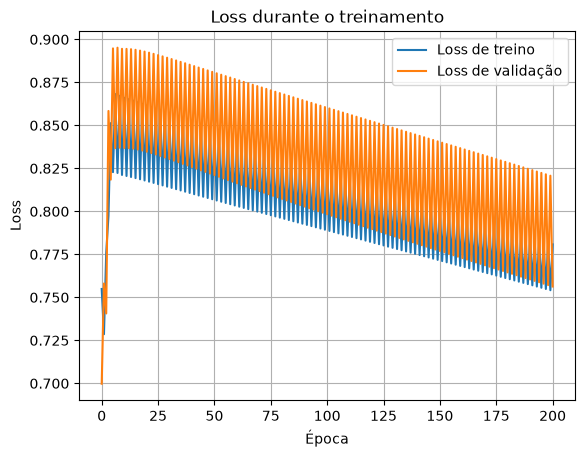

MELHOR LOSS DE VALIDAÇÃO: 0.700
NÚMERO DE ÉPOCAS: 201
teste com learning_rate = 0.5:


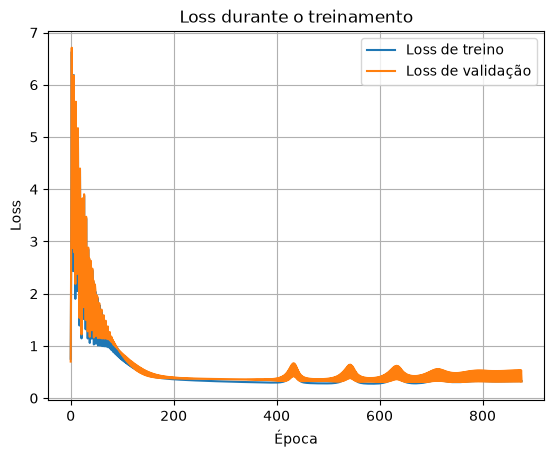

MELHOR LOSS DE VALIDAÇÃO: 0.308
NÚMERO DE ÉPOCAS: 877
teste com learning_rate = 0.01:


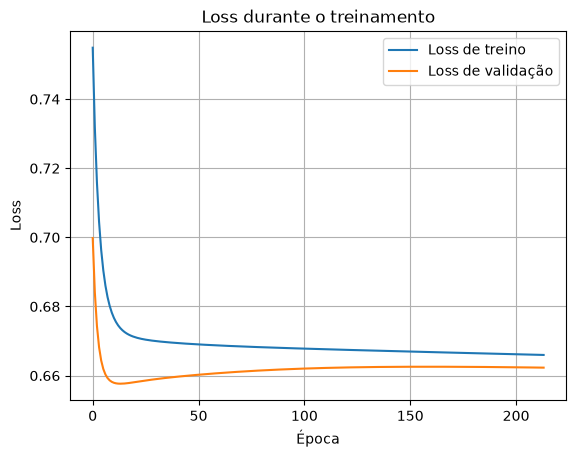

MELHOR LOSS DE VALIDAÇÃO: 0.658
NÚMERO DE ÉPOCAS: 214
teste com learning_rate = 0.05:


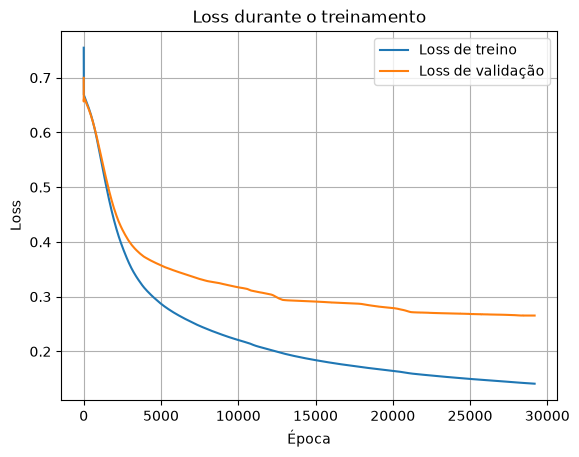

MELHOR LOSS DE VALIDAÇÃO: 0.265
NÚMERO DE ÉPOCAS: 29180
teste com learning_rate = 0.001:


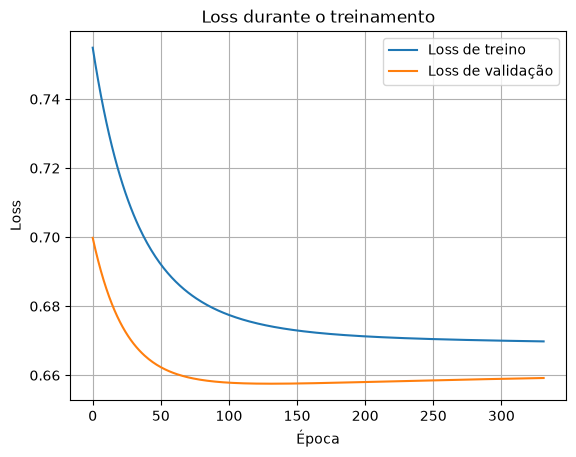

MELHOR LOSS DE VALIDAÇÃO: 0.658
NÚMERO DE ÉPOCAS: 332
teste com learning_rate = 0.005:


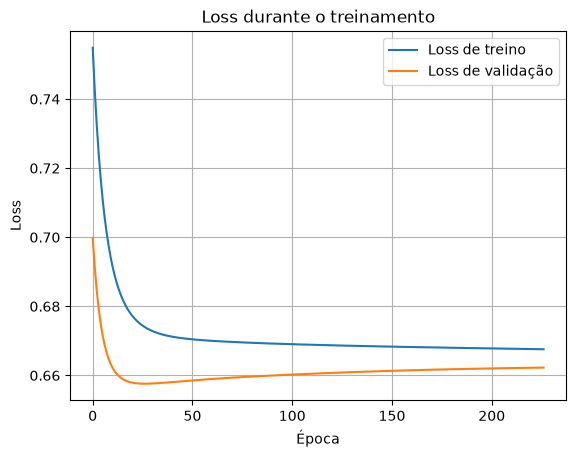

MELHOR LOSS DE VALIDAÇÃO: 0.658
NÚMERO DE ÉPOCAS: 227
teste com learning_rate = 0.0001:


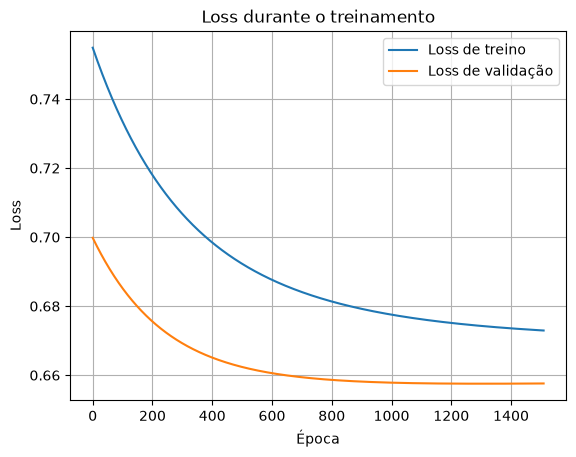

MELHOR LOSS DE VALIDAÇÃO: 0.658
NÚMERO DE ÉPOCAS: 1510
teste com learning_rate = 0.0005:


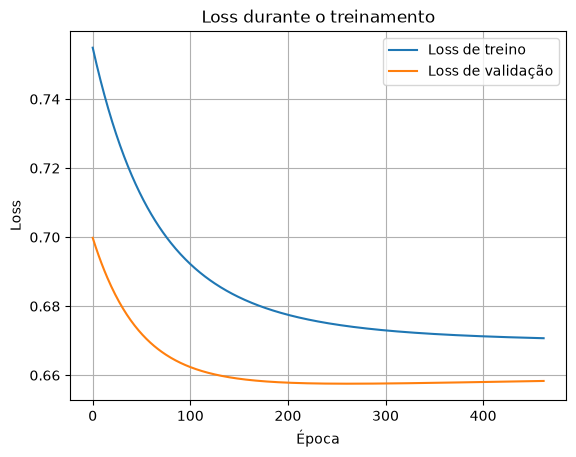

MELHOR LOSS DE VALIDAÇÃO: 0.658
NÚMERO DE ÉPOCAS: 463


In [ ]:
initial_params = he_init_params(np.random.default_rng(7), n_units)

for lr in experiment_lrs:
    print('='*80) 
    print(f'teste com learning_rate = {lr}:') 

    W1, b1, W2, b2 = (param.copy() for param in initial_params)

    # treinamento
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5
    
    for _ in range(epochs):
        # forward pass
        y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)
        history_loss_train.append(bce(y_train, y_hat))
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)

        # early stopping, com restore best weights
        loss_val = bce(y_val, y_hat_val)
        history_loss_val.append(loss_val)
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
                
        if count_patience >= patience:
            break

        # backward pass
        dW1, db1, dW2, db2 = backward(X_train_norm, y_train, W2, Z1, A1, y_hat)

        # gradient descent
        W1 = W1 - lr * dW1
        b1 = b1 - lr * db1
        W2 = W2 - lr * dW2
        b2 = b2 - lr * db2

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    print(f'MELHOR LOSS DE VALIDAÇÃO: {best_val:.3f}')
    print(f'NÚMERO DE ÉPOCAS: {len(history_loss_train)}')

usei os mesmos pesos iniciais em todos os testes, com 256 unidades na camada oculta e patience de 200 épocas. a taxa de 5e-2 teve a menor BCE de validação (0.265), mas levou 29180 épocas. o lr de 5e-1 chegou a uma perda um pouco maior (0.308) em só 877 épocas, mas a curva oscilou bastante. com 1e-1 a oscilação foi ainda mais forte e o treinamento parou em 201 épocas com BCE de 0.7. os lr's de 1e-2 ou menores ficaram perto de 0.65, que provavelmente melhoraria com um patience maior e um número maior de épocas, mas aí o tempo para convergir aumenta bastante. então, nessa arquitetura e com essa regra de parada, 5e-2 foi a melhor escolha pela perda final, mesmo não sendo a mais rápida de todas.

#### 10. Substitua a função de ativação utilizada na camada oculta por outra função de ativação não-linear. Compare o comportamento dessa configuração com a arquitetura original. Discuta, experimentalmente, aspectos como velocidade de convergência e qualidade da classificação.

In [51]:
epochs = 100000
patience = 200
n_units = 256
lr = 5e-2

vou comparar a função de ativação da camada oculta original (ReLU) com a Swish (Swish = x * sigmoid(beta * x), vou usar beta = 1 que é a forma mais comum).

In [52]:
def swish(x):
    return x * sigmoid(x)

# derivada da swish para usar no backward pass
def swish_grad(x):
    sig = sigmoid(x)
    return sig + x * sig * (1 - sig) 

primeiro, avaliando a arquitetura original com ReLU

In [53]:
def forward_relu(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    y_hat = sigmoid(A1 @ W2 + b2)
    return y_hat, A1, Z1

In [54]:
def backward_relu(X, y, W2, Z1, A1, A2):
    y = y.reshape(-1, 1)
    n = len(y)

    dZ2 = (A2 - y) / n
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [55]:
def predict_relu(X, W1, b1, W2, b2):
    prob_val, _, _ = forward_relu(X, W1, b1, W2, b2)
    pred_val = (prob_val.ravel() >= 0.5).astype(int)
    return pred_val

In [56]:
print(f'avaliando a arquitetura com função de ativação ReLU:') 

resultados = []
# uso de 5 seeds para inicialização dos pesos para analisar média e desvio padrao
for seed in [7, 10, 15, 101, 200]:
    rng_model = np.random.default_rng(seed)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5
    for _ in range(epochs):
        # forward pass
        y_hat, A1, Z1 = forward_relu(X_train_norm, W1, b1, W2, b2)
        history_loss_train.append(bce(y_train, y_hat))
        y_hat_val, _, _ = forward_relu(X_val_norm, W1, b1, W2, b2)

        # early stopping, com restore best weights
        loss_val = bce(y_val, y_hat_val)
        history_loss_val.append(loss_val)
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break

        # backward pass
        dW1, db1, dW2, db2 = backward_relu(X_train_norm, y_train, W2, Z1, A1, y_hat)

        # gradient descent
        W1 = W1 - lr * dW1
        b1 = b1 - lr * db1
        W2 = W2 - lr * dW2
        b2 = b2 - lr * db2

    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    # plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    # plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    # plt.title('Loss durante o treinamento')
    # plt.xlabel('Época')
    # plt.ylabel('Loss')
    # plt.legend()
    # plt.grid()
    # plt.show()
    pred_val = predict_relu(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

avaliando a arquitetura com função de ativação ReLU:
NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 28246.200
TEMPO DE TREINAMENTO: 35.836s +- 4.413s
ACURÁCIA: 0.925 +- 0.008
F1-SCORE: 0.925 +- 0.008
LOSS DE VALIDAÇÃO: 0.259 +- 0.007


agora, avaliando a arquitetura com a função de ativação Swish

In [57]:
def forward_swish(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = swish(Z1)
    y_hat = sigmoid(A1 @ W2 + b2)
    return y_hat, A1, Z1

In [58]:
def backward_swish(X, y, W2, Z1, A1, A2):
    y = y.reshape(-1, 1)
    n = len(y)

    dZ2 = (A2 - y) / n
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * swish_grad(Z1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [59]:
def predict_swish(X, W1, b1, W2, b2):
    prob_val, _, _ = forward_swish(X, W1, b1, W2, b2)
    pred_val = (prob_val.ravel() >= 0.5).astype(int)
    return pred_val

In [60]:
print(f'avaliando a arquitetura com função de ativação Swish:') 

resultados = []
# uso de 5 seeds para inicialização dos pesos para analisar média e desvio padrao
for seed in [7, 10, 15, 101, 200]:
    rng_model = np.random.default_rng(seed)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5
    for _ in range(epochs):
        # forward pass
        y_hat, A1, Z1 = forward_swish(X_train_norm, W1, b1, W2, b2)
        history_loss_train.append(bce(y_train, y_hat))
        y_hat_val, _, _ = forward_swish(X_val_norm, W1, b1, W2, b2)

        # early stopping, com restore best weights
        loss_val = bce(y_val, y_hat_val)
        history_loss_val.append(loss_val)
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break

        # backward pass
        dW1, db1, dW2, db2 = backward_swish(X_train_norm, y_train, W2, Z1, A1, y_hat)

        # gradient descent
        W1 = W1 - lr * dW1
        b1 = b1 - lr * db1
        W2 = W2 - lr * dW2
        b2 = b2 - lr * db2

    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    # plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    # plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    # plt.title('Loss durante o treinamento')
    # plt.xlabel('Época')
    # plt.ylabel('Loss')
    # plt.legend()
    # plt.grid()
    # plt.show()
    pred_val = predict_swish(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

avaliando a arquitetura com função de ativação Swish:
NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 14927.800
TEMPO DE TREINAMENTO: 45.174s +- 61.380s
ACURÁCIA: 0.705 +- 0.188
F1-SCORE: 0.693 +- 0.199
LOSS DE VALIDAÇÃO: 0.491 +- 0.231


comparação com a mesma arquitetura de 256 unidades ocultas, lr de 5e-2, patience de 200 e as mesmas 5 seeds. a ReLU teve resultados melhores e mais estáveis, acurácia e F1-score de 0.925 +- 0.008 e BCE de 0.259 +- 0.007. já com a Swish, a acurácia ficou em 0.705 +- 0.188, o F1-score em 0.693 +- 0.199 e a BCE em 0.491 +- 0.231. a Swish parou em menos épocas em média (14927 contra 28246 da ReLU), mas não chegou na mesma performance de classificação, então não convergiu mais rápido para uma solução melhor. o tempo médio de treinamento por seed foi de 45 +- 61 s com a Swish e 35 +- 4 s com a ReLU. o tempo da Swish variou bastante entre as seeds, igual as suas métricas. nesse experimento, a ReLU foi a melhor analisando a perda, a performance e a estabilidade entre as inicializações.

#### 11. Avalie o efeito da inicialização dos parâmetros. Compare a He initialization com uma inicialização aleatória de pequena amplitude. Discuta o impacto observado sobre a convergência do treinamento e o resultado final.

In [51]:
epochs = 100000
patience = 200
n_units = 256
lr = 5e-2

In [52]:
def he_init_params(rng, n_hidden):
    W1 = rng.normal(0, np.sqrt(2 / 2), size=(2, n_hidden))
    b1 = np.zeros((1, n_hidden))
    W2 = rng.normal(0, np.sqrt(2 / n_hidden), size=(n_hidden, 1))
    b2 = np.zeros((1, 1))
    return W1, b1, W2, b2

In [53]:
def aleat_init_params(rng, n_hidden, std):
    W1 = rng.normal(0, std, size=(2, n_hidden))
    b1 = np.zeros((1, n_hidden))
    W2 = rng.normal(0, std, size=(n_hidden, 1))
    b2 = np.zeros((1, 1))
    return W1, b1, W2, b2

In [54]:
def forward(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)
    y_hat = sigmoid(A1 @ W2 + b2)
    return y_hat, A1, Z1

In [55]:
def backward(X, y, W2, Z1, A1, A2):
    y = y.reshape(-1, 1)
    n = len(y)

    dZ2 = (A2 - y) / n
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [56]:
def predict(X, W1, b1, W2, b2):
    prob_val, _, _ = forward(X, W1, b1, W2, b2)
    pred_val = (prob_val.ravel() >= 0.5).astype(int)
    return pred_val

avaliando a arquitetura com a inicialização He dos pesos:


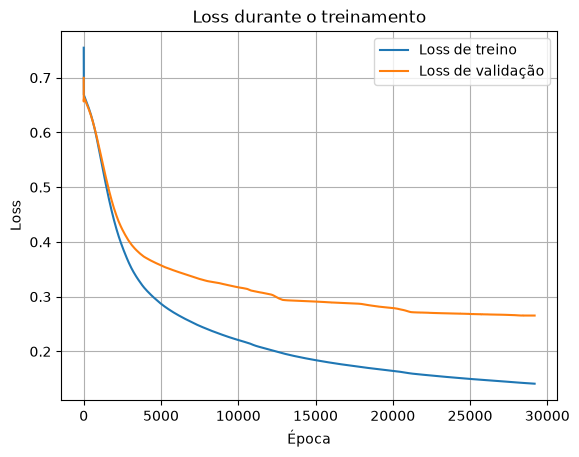

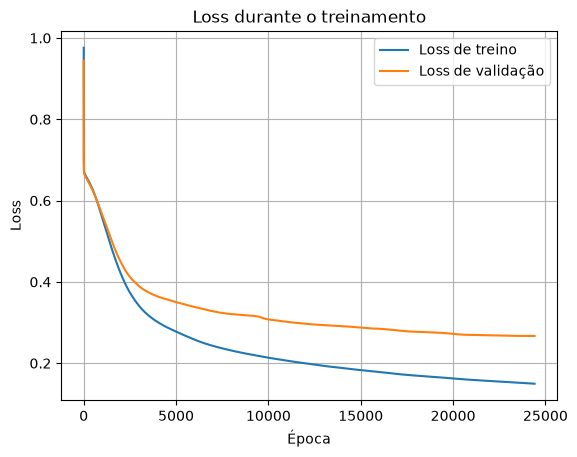

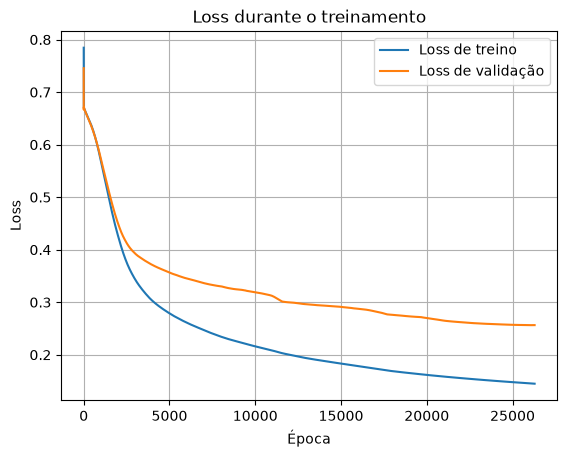

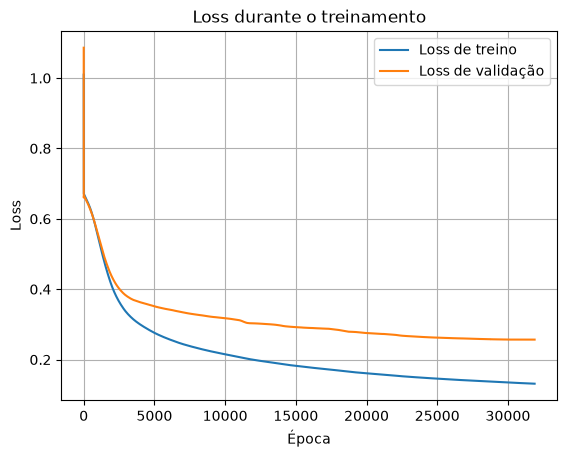

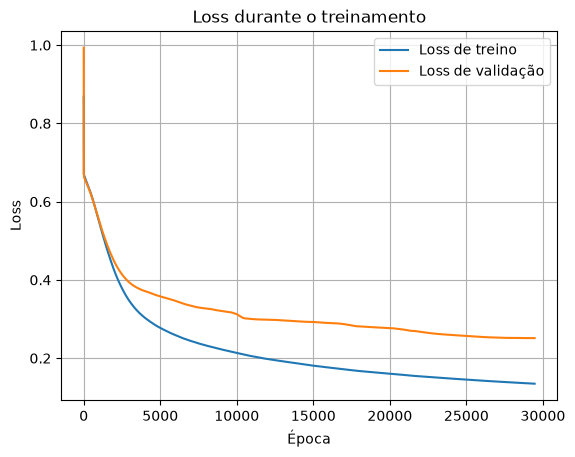

NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 28246.200
TEMPO DE TREINAMENTO: 18.843s +- 1.808s
ACURÁCIA: 0.925 +- 0.008
F1-SCORE: 0.925 +- 0.008
LOSS DE VALIDAÇÃO: 0.259 +- 0.007


In [66]:
print(f'avaliando a arquitetura com a inicialização He dos pesos:') 

resultados = []
# uso de 5 seeds para inicialização dos pesos para analisar média e desvio padrao
for seed in [7, 10, 15, 101, 200]:
    rng_model = np.random.default_rng(seed)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5
    for _ in range(epochs):
        # forward pass
        y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)
        history_loss_train.append(bce(y_train, y_hat))
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)

        # early stopping, com restore best weights
        loss_val = bce(y_val, y_hat_val)
        history_loss_val.append(loss_val)
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break

        # backward pass
        dW1, db1, dW2, db2 = backward(X_train_norm, y_train, W2, Z1, A1, y_hat)

        # gradient descent
        W1 = W1 - lr * dW1
        b1 = b1 - lr * db1
        W2 = W2 - lr * dW2
        b2 = b2 - lr * db2

    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

avaliando a arquitetura com a inicialização aleatória com desvio padrao = 0.001 dos pesos:


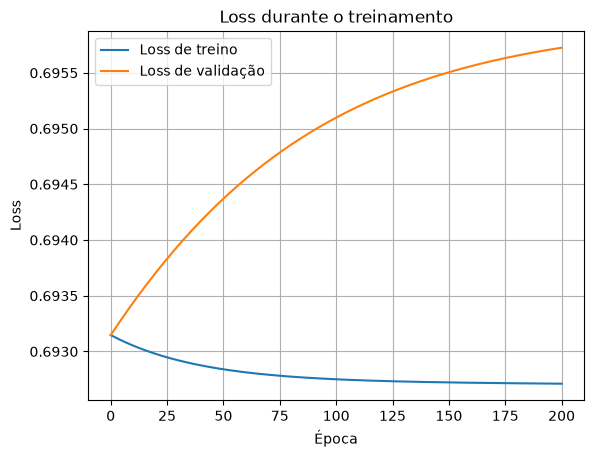

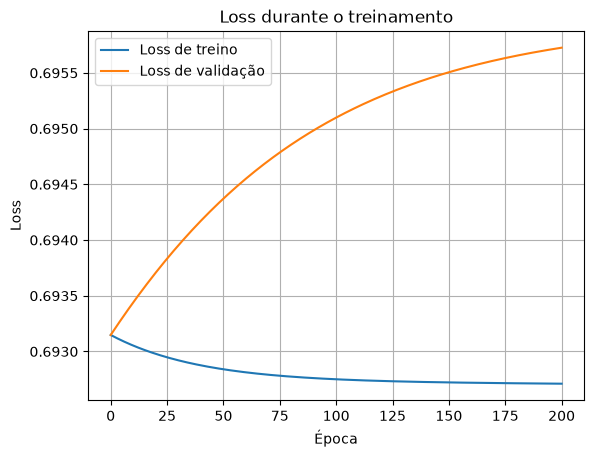

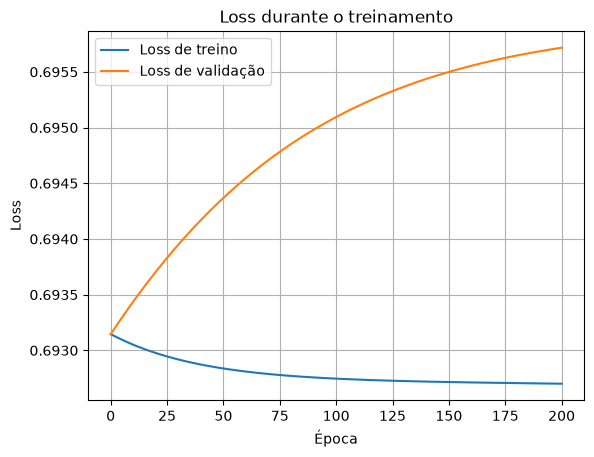

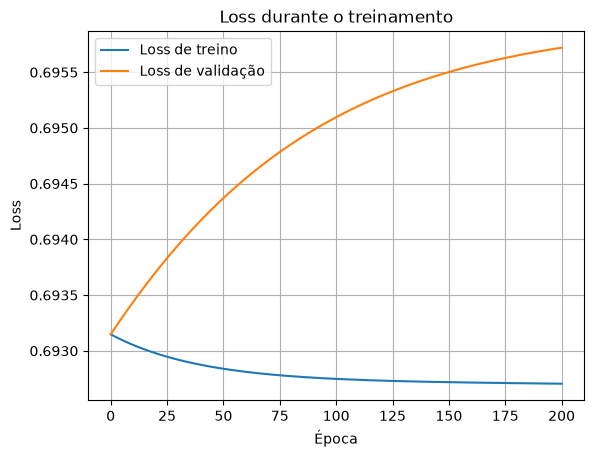

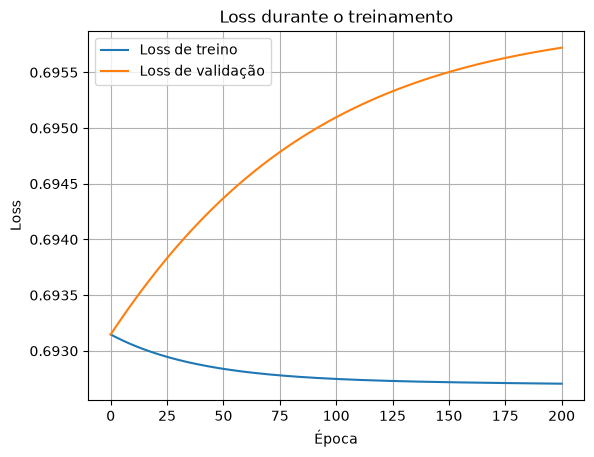

NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 201.000
TEMPO DE TREINAMENTO: 0.133s +- 0.006s
ACURÁCIA: 0.537 +- 0.045
F1-SCORE: 0.455 +- 0.090
LOSS DE VALIDAÇÃO: 0.693 +- 0.000


In [67]:
print(f'avaliando a arquitetura com a inicialização aleatória com desvio padrao = 0.001 dos pesos:') 

resultados = []
# uso de 5 seeds para inicialização dos pesos para analisar média e desvio padrao
for seed in [7, 10, 15, 101, 200]:
    rng_model = np.random.default_rng(seed)
    W1, b1, W2, b2 = aleat_init_params(rng_model, n_units, 1e-3)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5
    for _ in range(epochs):
        # forward pass
        y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)
        history_loss_train.append(bce(y_train, y_hat))
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)

        # early stopping, com restore best weights
        loss_val = bce(y_val, y_hat_val)
        history_loss_val.append(loss_val)
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break

        # backward pass
        dW1, db1, dW2, db2 = backward(X_train_norm, y_train, W2, Z1, A1, y_hat)

        # gradient descent
        W1 = W1 - lr * dW1
        b1 = b1 - lr * db1
        W2 = W2 - lr * dW2
        b2 = b2 - lr * db2

    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

avaliando a arquitetura com a inicialização aleatória com desvio padrao = 0.01 dos pesos:


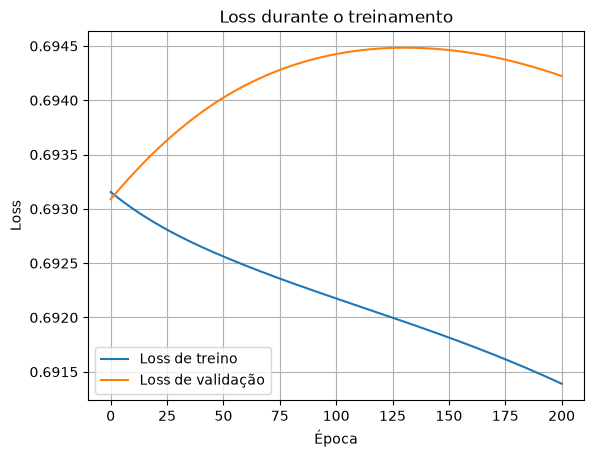

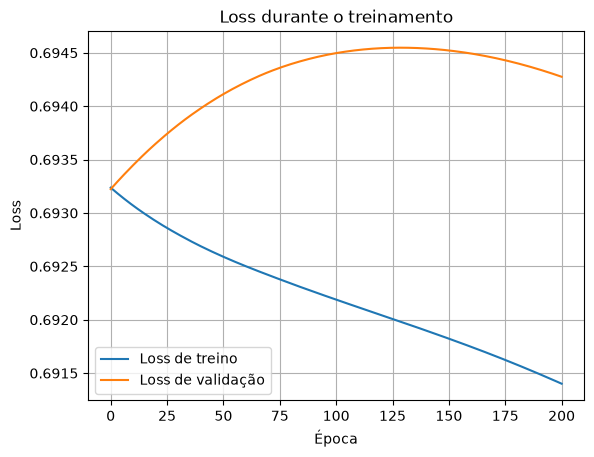

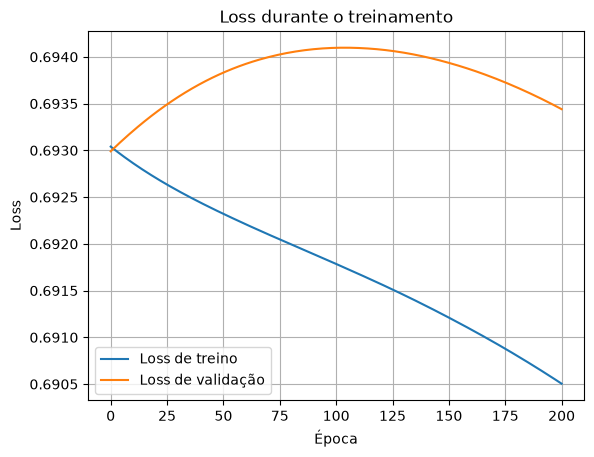

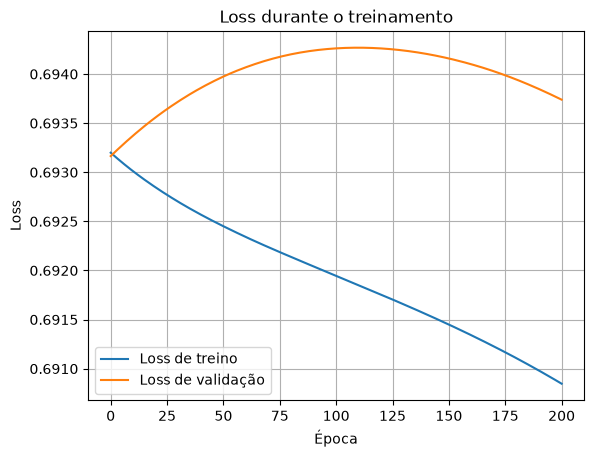

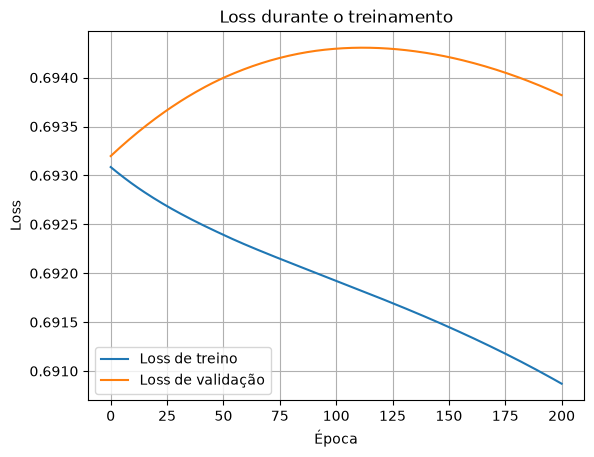

NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 201.000
TEMPO DE TREINAMENTO: 0.143s +- 0.017s
ACURÁCIA: 0.537 +- 0.045
F1-SCORE: 0.455 +- 0.090
LOSS DE VALIDAÇÃO: 0.693 +- 0.000


In [68]:
print(f'avaliando a arquitetura com a inicialização aleatória com desvio padrao = 0.01 dos pesos:') 

resultados = []
# uso de 5 seeds para inicialização dos pesos para analisar média e desvio padrao
for seed in [7, 10, 15, 101, 200]:
    rng_model = np.random.default_rng(seed)
    W1, b1, W2, b2 = aleat_init_params(rng_model, n_units, 1e-2)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5
    for _ in range(epochs):
        # forward pass
        y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)
        history_loss_train.append(bce(y_train, y_hat))
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)

        # early stopping, com restore best weights
        loss_val = bce(y_val, y_hat_val)
        history_loss_val.append(loss_val)
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break

        # backward pass
        dW1, db1, dW2, db2 = backward(X_train_norm, y_train, W2, Z1, A1, y_hat)

        # gradient descent
        W1 = W1 - lr * dW1
        b1 = b1 - lr * db1
        W2 = W2 - lr * dW2
        b2 = b2 - lr * db2

    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

comparei a inicialização He com duas inicializações aleatórias com desvio padrão de 0.001 e 0.01, mantendo a mesma arquitetura, learning rate, patience e as mesmas 5 seeds. com He, a rede teve acurácia e F1-score de 0.925 +- 0.008 e BCE de validação de 0.259 +- 0.007. já com os desvios pequenos, os resultados foram praticamente iguais, acurácia de 0.537 +- 0.045, F1-score de 0.455 +- 0.090 e BCE de 0.693. nos dois casos o treinamento parou em 201 épocas, já que a perda de validação não melhorou durante as 200 épocas de patience. o tempo de treinamento com as inicializacoes aleatórias foi bem menor, mas é devido ao early stop, e a qualidade das predições foi bem inferior. nesse experimento, a inicialização He foi bem melhor tanto no resultado final quanto na estabilidade.

#### 12. Finalmente, retreine a mesma arquitetura selecionada a partir dos experimentos anteriores utilizando diferentes seeds. Avalie a variabilidade dos resultados obtidos.

- arquitetura selecionada: 2 unidades -> 256 unidades -> 1 unidades, com a função de ativação da camada oculta sendo a ReLU.

- inicialização dos parâmetros: He

- learning rate: 0.05

In [69]:
epochs = 100000
patience = 200
n_units = 256
lr = 5e-2

In [ ]:
print(f'avaliando a arquitetura final em 10 seeds:') 

resultados = []
# uso de 10 seeds para inicialização dos pesos para analisar média e desvio padrao
for seed in [7, 10, 15, 101, 200, 201, 300, 303, 400, 404]:
    rng_model = np.random.default_rng(seed)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5
    for _ in range(epochs):
        # forward pass
        y_hat, A1, Z1 = forward(X_train_norm, W1, b1, W2, b2)
        history_loss_train.append(bce(y_train, y_hat))
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)

        # early stopping, com restore best weights
        loss_val = bce(y_val, y_hat_val)
        history_loss_val.append(loss_val)
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break

        # backward pass
        dW1, db1, dW2, db2 = backward(X_train_norm, y_train, W2, Z1, A1, y_hat)

        # gradient descent
        W1 = W1 - lr * dW1
        b1 = b1 - lr * db1
        W2 = W2 - lr * dW2
        b2 = b2 - lr * db2

    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    # plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    # plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    # plt.title('Loss durante o treinamento')
    # plt.xlabel('Época')
    # plt.ylabel('Loss')
    # plt.legend()
    # plt.grid()
    # plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

avaliando a arquitetura final em 10 seeds:
NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 28165.000
TEMPO DE TREINAMENTO: 19.397s +- 2.433s
ACURÁCIA: 0.925 +- 0.014
F1-SCORE: 0.925 +- 0.014
LOSS DE VALIDAÇÃO: 0.260 +- 0.008


acurácia e f1-score com desvio padrão de 1.4 pontos percentuais, e a BCE com 0.008 de desvio padrão, bem baixo para 10 seeds, mas o split de dados permaneceu fixo, então essa é a medida de variabilidade da inicialização dos pesos.

#### BÔNUS 1. Substitua o gradient descent utilizado no treinamento por stochastic gradient descent (SGD), atualizando os parâmetros da rede a partir de uma, duas ou quatro amostras por vez. Compare o comportamento do treinamento com o método usado anteriormente, considerando a evolução da função de perda e o desempenho final da rede.

In [63]:
epochs = 100000
patience = 200
n_units = 256
lr = 5e-2
batch_size = 1

avaliando a arquitetura final com SGD:


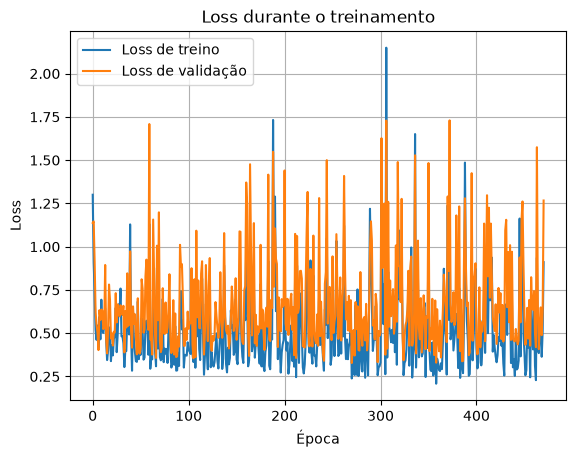

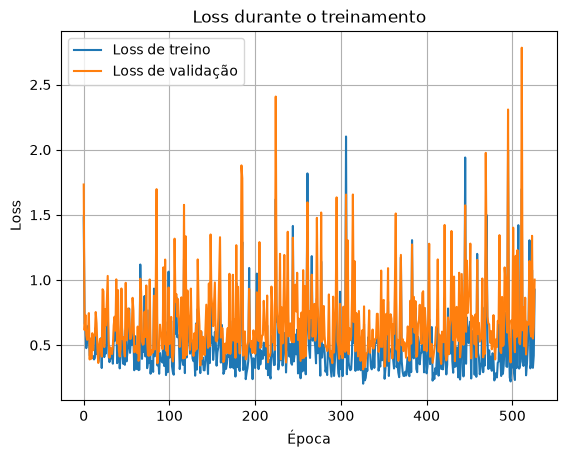

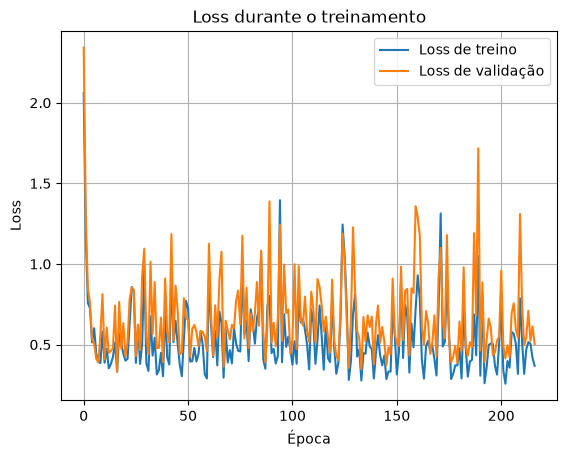

NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 405.000
TEMPO DE TREINAMENTO: 4.117s +- 1.680s
ACURÁCIA: 0.861 +- 0.005
F1-SCORE: 0.860 +- 0.005
LOSS DE VALIDAÇÃO: 0.324 +- 0.010


In [64]:
print(f'avaliando a arquitetura final com SGD:')

resultados = []
# uso de 3 seeds
for seed in [7, 10, 15]:
    rng_model = np.random.default_rng(seed)
    rng_batch = np.random.default_rng(seed+10)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5

    # loop das épocas
    for _ in range(epochs):
        # loop dos steps (1 step = 1 batch processado)
        idx_permutado = rng_batch.permutation(len(X_train_norm))
        for i in range(0, len(X_train_norm), batch_size):
            idx = idx_permutado[i:i+batch_size]
            X_batch_train = X_train_norm[idx]
            y_batch_train = y_train[idx]

            # forward pass
            y_hat, A1, Z1 = forward(X_batch_train, W1, b1, W2, b2)

            # backward pass
            dW1, db1, dW2, db2 = backward(X_batch_train, y_batch_train, W2, Z1, A1, y_hat)

            # gradient descent
            W1 = W1 - lr * dW1
            b1 = b1 - lr * db1
            W2 = W2 - lr * dW2
            b2 = b2 - lr * db2

        y_hat_train, _, _ = forward(X_train_norm, W1, b1, W2, b2)
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)
        loss_val = bce(y_val, y_hat_val)
        history_loss_train.append(bce(y_train, y_hat_train))
        history_loss_val.append(loss_val)

        # early stopping, com restore best weights
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break


    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

In [65]:
batch_size = 2

avaliando a arquitetura final com mini-batch SGD (batch_size = 2):


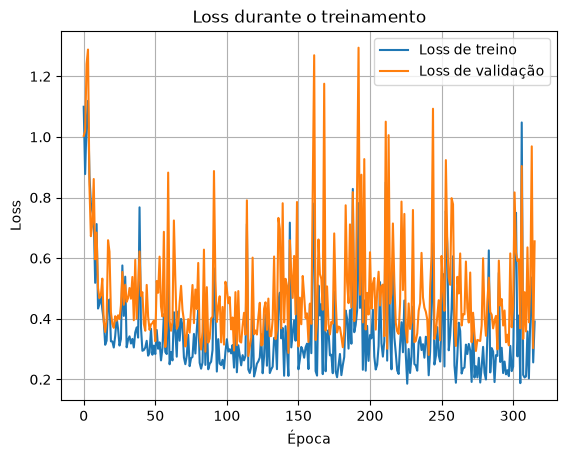

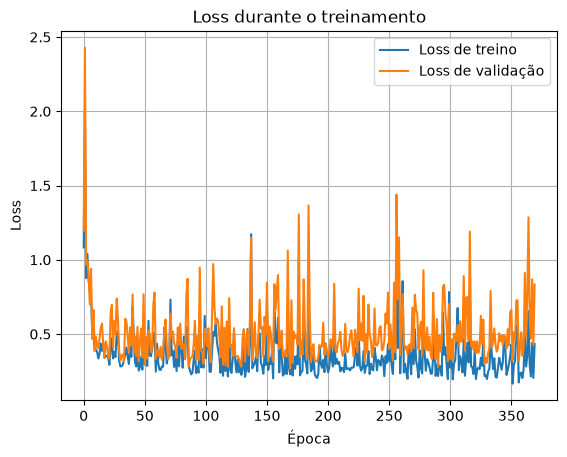

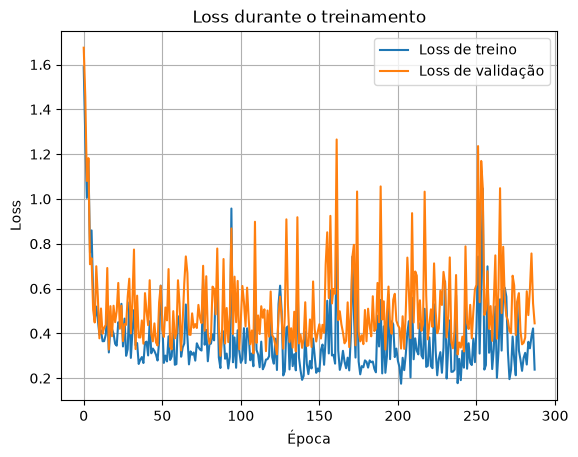

NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 324.667
TEMPO DE TREINAMENTO: 1.843s +- 0.240s
ACURÁCIA: 0.894 +- 0.005
F1-SCORE: 0.893 +- 0.005
LOSS DE VALIDAÇÃO: 0.282 +- 0.016


In [66]:
print(f'avaliando a arquitetura final com mini-batch SGD (batch_size = 2):')

resultados = []
# uso de 3 seeds
for seed in [7, 10, 15]:
    rng_model = np.random.default_rng(seed)
    rng_batch = np.random.default_rng(seed+10)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5

    # loop das épocas
    for _ in range(epochs):
        # loop dos steps (1 step = 1 batch processado)
        idx_permutado = rng_batch.permutation(len(X_train_norm))
        for i in range(0, len(X_train_norm), batch_size):
            idx = idx_permutado[i:i+batch_size]
            X_batch_train = X_train_norm[idx]
            y_batch_train = y_train[idx]

            # forward pass
            y_hat, A1, Z1 = forward(X_batch_train, W1, b1, W2, b2)

            # backward pass
            dW1, db1, dW2, db2 = backward(X_batch_train, y_batch_train, W2, Z1, A1, y_hat)

            # gradient descent
            W1 = W1 - lr * dW1
            b1 = b1 - lr * db1
            W2 = W2 - lr * dW2
            b2 = b2 - lr * db2

        y_hat_train, _, _ = forward(X_train_norm, W1, b1, W2, b2)
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)
        loss_val = bce(y_val, y_hat_val)
        history_loss_train.append(bce(y_train, y_hat_train))
        history_loss_val.append(loss_val)

        # early stopping, com restore best weights
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break


    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

In [67]:
batch_size = 4

avaliando a arquitetura final com mini-batch SGD (batch_size = 4):


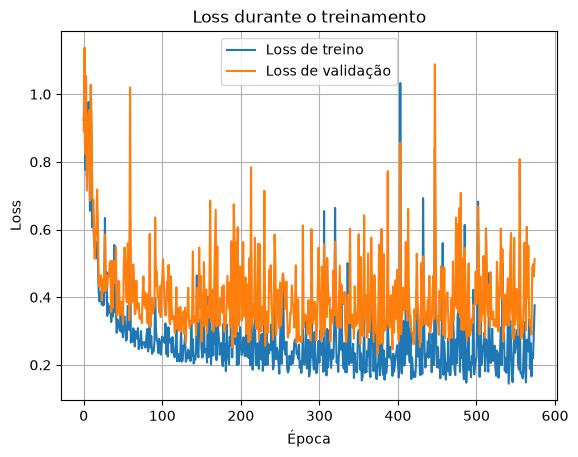

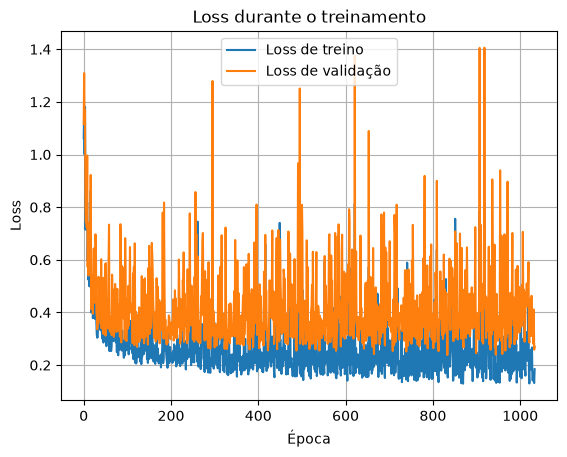

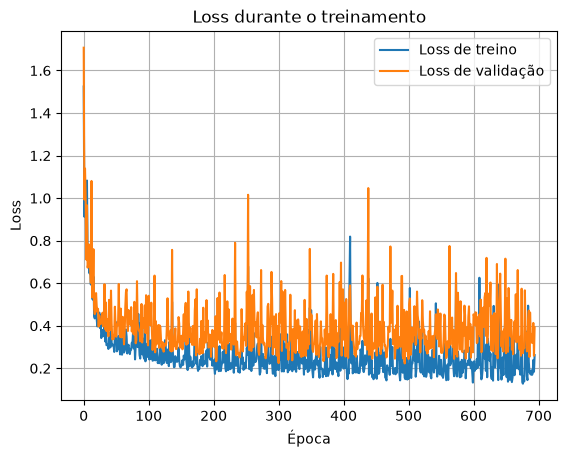

NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 768.000
TEMPO DE TREINAMENTO: 2.448s +- 0.721s
ACURÁCIA: 0.914 +- 0.017
F1-SCORE: 0.913 +- 0.018
LOSS DE VALIDAÇÃO: 0.232 +- 0.008


In [68]:
print(f'avaliando a arquitetura final com mini-batch SGD (batch_size = 4):')

resultados = []
# uso de 3 seeds
for seed in [7, 10, 15]:
    rng_model = np.random.default_rng(seed)
    rng_batch = np.random.default_rng(seed+10)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5

    # loop das épocas
    for _ in range(epochs):
        # loop dos steps (1 step = 1 batch processado)
        idx_permutado = rng_batch.permutation(len(X_train_norm))
        for i in range(0, len(X_train_norm), batch_size):
            idx = idx_permutado[i:i+batch_size]
            X_batch_train = X_train_norm[idx]
            y_batch_train = y_train[idx]

            # forward pass
            y_hat, A1, Z1 = forward(X_batch_train, W1, b1, W2, b2)

            # backward pass
            dW1, db1, dW2, db2 = backward(X_batch_train, y_batch_train, W2, Z1, A1, y_hat)

            # gradient descent
            W1 = W1 - lr * dW1
            b1 = b1 - lr * db1
            W2 = W2 - lr * dW2
            b2 = b2 - lr * db2

        y_hat_train, _, _ = forward(X_train_norm, W1, b1, W2, b2)
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)
        loss_val = bce(y_val, y_hat_val)
        history_loss_train.append(bce(y_train, y_hat_train))
        history_loss_val.append(loss_val)

        # early stopping, com restore best weights
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break


    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

In [73]:
batch_size = 16

avaliando a arquitetura final com mini-batch SGD (batch_size = 16):


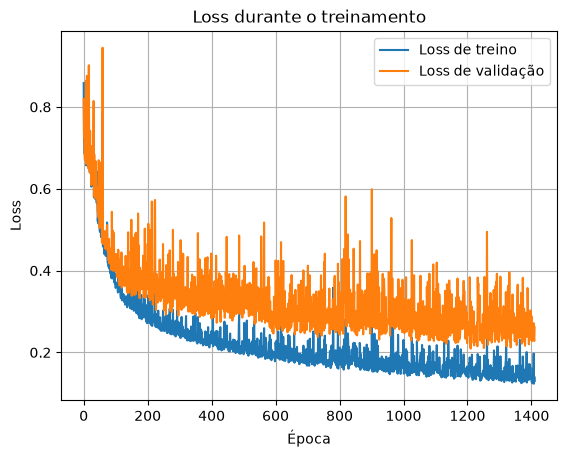

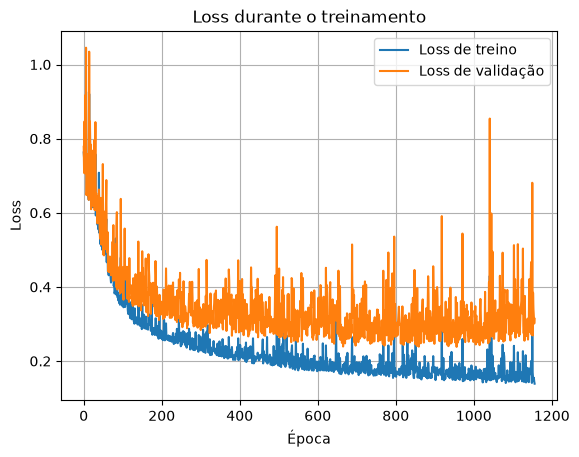

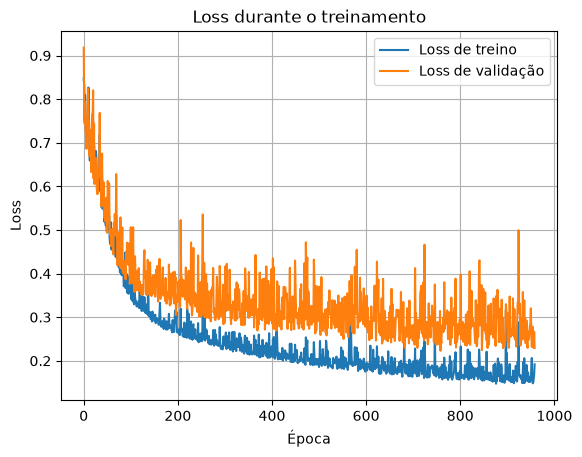

NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 1175.667
TEMPO DE TREINAMENTO: 1.586s +- 0.351s
ACURÁCIA: 0.917 +- 0.008
F1-SCORE: 0.916 +- 0.009
LOSS DE VALIDAÇÃO: 0.223 +- 0.014


In [74]:
print(f'avaliando a arquitetura final com mini-batch SGD (batch_size = 16):')

resultados = []
# uso de 3 seeds
for seed in [7, 10, 15]:
    rng_model = np.random.default_rng(seed)
    rng_batch = np.random.default_rng(seed+10)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5

    # loop das épocas
    for _ in range(epochs):
        # loop dos steps (1 step = 1 batch processado)
        idx_permutado = rng_batch.permutation(len(X_train_norm))
        for i in range(0, len(X_train_norm), batch_size):
            idx = idx_permutado[i:i+batch_size]
            X_batch_train = X_train_norm[idx]
            y_batch_train = y_train[idx]

            # forward pass
            y_hat, A1, Z1 = forward(X_batch_train, W1, b1, W2, b2)

            # backward pass
            dW1, db1, dW2, db2 = backward(X_batch_train, y_batch_train, W2, Z1, A1, y_hat)

            # gradient descent
            W1 = W1 - lr * dW1
            b1 = b1 - lr * db1
            W2 = W2 - lr * dW2
            b2 = b2 - lr * db2

        y_hat_train, _, _ = forward(X_train_norm, W1, b1, W2, b2)
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)
        loss_val = bce(y_val, y_hat_val)
        history_loss_train.append(bce(y_train, y_hat_train))
        history_loss_val.append(loss_val)

        # early stopping, com restore best weights
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break


    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

In [75]:
batch_size = 32

avaliando a arquitetura final com mini-batch SGD (batch_size = 32):


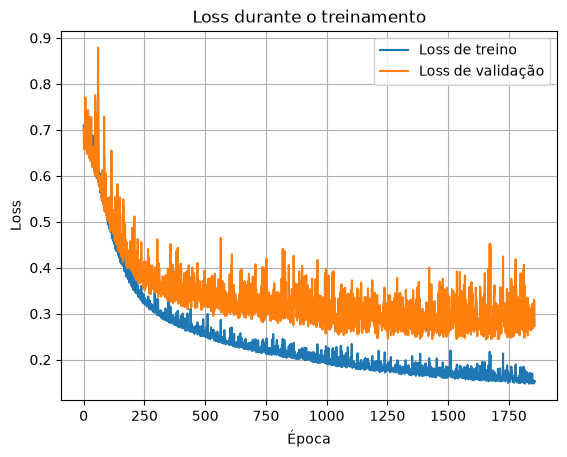

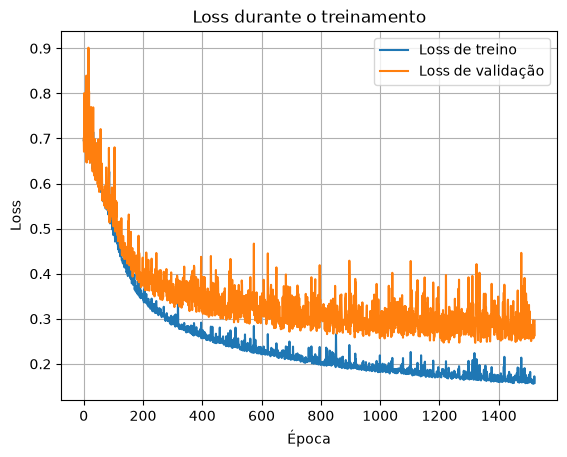

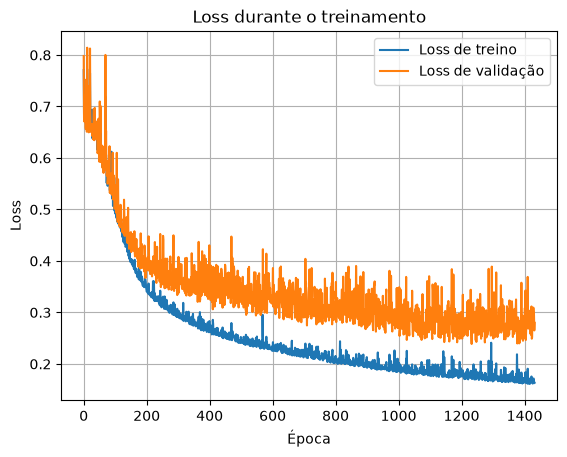

NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: 1604.000
TEMPO DE TREINAMENTO: 1.659s +- 0.234s
ACURÁCIA: 0.911 +- 0.024
F1-SCORE: 0.910 +- 0.025
LOSS DE VALIDAÇÃO: 0.243 +- 0.004


In [76]:
print(f'avaliando a arquitetura final com mini-batch SGD (batch_size = 32):')

resultados = []
# uso de 3 seeds
for seed in [7, 10, 15]:
    rng_model = np.random.default_rng(seed)
    rng_batch = np.random.default_rng(seed+10)
    W1, b1, W2, b2 = he_init_params(rng_model, n_units)

    # treinamento
    inicio_treino = time.perf_counter()
    history_loss_train = []
    history_loss_val = []
    count_patience = 0
    best_val = 1e5

    # loop das épocas
    for _ in range(epochs):
        # loop dos steps (1 step = 1 batch processado)
        idx_permutado = rng_batch.permutation(len(X_train_norm))
        for i in range(0, len(X_train_norm), batch_size):
            idx = idx_permutado[i:i+batch_size]
            X_batch_train = X_train_norm[idx]
            y_batch_train = y_train[idx]

            # forward pass
            y_hat, A1, Z1 = forward(X_batch_train, W1, b1, W2, b2)

            # backward pass
            dW1, db1, dW2, db2 = backward(X_batch_train, y_batch_train, W2, Z1, A1, y_hat)

            # gradient descent
            W1 = W1 - lr * dW1
            b1 = b1 - lr * db1
            W2 = W2 - lr * dW2
            b2 = b2 - lr * db2

        y_hat_train, _, _ = forward(X_train_norm, W1, b1, W2, b2)
        y_hat_val, _, _ = forward(X_val_norm, W1, b1, W2, b2)
        loss_val = bce(y_val, y_hat_val)
        history_loss_train.append(bce(y_train, y_hat_train))
        history_loss_val.append(loss_val)

        # early stopping, com restore best weights
        if loss_val < best_val:
            best_val = loss_val
            count_patience = 0
            best_params = W1.copy(), b1.copy(), W2.copy(), b2.copy()
        else:
            count_patience += 1
            
        if count_patience >= patience:
            break


    tempo_treinamento = time.perf_counter() - inicio_treino

    # restaurar melhores parametros
    W1, b1, W2, b2 = best_params

    # avaliação
    plt.plot(np.arange(len(history_loss_train)), history_loss_train, label='Loss de treino')
    plt.plot(np.arange(len(history_loss_val)), history_loss_val, label='Loss de validação')
    plt.title('Loss durante o treinamento')
    plt.xlabel('Época')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()
    pred_val = predict(X_val_norm, W1, b1, W2, b2)
    acc_val, _, _, f1_val, _ = evaluate(y_val, pred_val)
    resultados.append({
        'acuracia': acc_val,
        'loss_val': best_val,
        'f1-score': f1_val,
        'epochs': len(history_loss_train),
        'tempo': tempo_treinamento
    })

acuracia_arr = np.array([r['acuracia'] for r in resultados])
f1_arr = np.array([np.mean(r['f1-score']) for r in resultados])
loss_val_arr = np.array([r['loss_val'] for r in resultados])
epochs_arr = np.array([r['epochs'] for r in resultados])
tempo_arr = np.array([r['tempo'] for r in resultados])
print(f'NÚMERO MÉDIO DE ÉPOCAS DE TREINAMENTO: {epochs_arr.mean():.3f}')
print(f'TEMPO DE TREINAMENTO: {tempo_arr.mean():.3f}s +- {tempo_arr.std(ddof=1):.3f}s')
print(f'ACURÁCIA: {acuracia_arr.mean():.3f} +- {acuracia_arr.std(ddof=1):.3f}')
print(f'F1-SCORE: {f1_arr.mean():.3f} +- {f1_arr.std(ddof=1):.3f}')
print(f'LOSS DE VALIDAÇÃO: {loss_val_arr.mean():.3f} +- {loss_val_arr.std(ddof=1):.3f}')

com batch_size=1, a perda de treino e validação oscilou bastante. com o batch_size = 2 e 4 amostras por atualização, a perda caiu mais, mas ainda teve vários picos. além desses pedidos no enunciado testei outros tamanhos, e com 16 e 32, as curvas ficaram mais suaves e a queda da perda ficou mais evidente. faz sentido porque lotes maiores usam mais amostras para calcular o gradiente em cada step/atualização. o gradient descent anterior tinha curvas bem mais estáveis, já que calculava o gradiente usando todo o conjunto de treino.

no desempenho final, batch_size=1 teve a pior acurácia média (0.861) e a maior BCE de validação (0.324). os melhores resultados ficaram com 4 e 16 amostras, acurácia de 0.914 e 0.917, e BCE de 0.232 e 0.223, respectivamente. com 32 amostras, a acurácia caiu um pouco para 0.911 e a BCE subiu para 0.243, então aumentar o lote não melhorou sempre o resultado. o gradient descent anterior chegou a 0.925 de acurácia, um pouco acima dos lotes testados, mas com BCE de 0.260, maior que a dos lotes 4 e 16. esses valores são uma comparação aproximada, já que aqui foram usados 3 seeds e no teste anterior foram 10.

#### BÔNUS 2. Estenda a MLP para utilizar duas camadas ocultas, considerando diferentes larguras para essas camadas. Compare o comportamento dessa arquitetura com a MLP de uma única camada oculta, discutindo o impacto da profundidade e da capacidade da rede sobre os resultados obtidos.